In [42]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

In [43]:
dataset = pd.read_csv("used_car_resale_dataset.csv")

In [44]:
dataset.shape

(2006, 8)

In [45]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2006 entries, 0 to 2005
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   brand          2006 non-null   object 
 1   model_year     2006 non-null   int64  
 2   engine_size    1866 non-null   float64
 3   mileage        1876 non-null   float64
 4   fuel_type      1886 non-null   object 
 5   transmission   2006 non-null   object 
 6   owner_count    2006 non-null   int64  
 7   selling_price  2006 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 125.5+ KB


In [46]:
dataset.head(10)

,brand,model_year,engine_size,mileage,fuel_type,transmission,owner_count,selling_price
0,Audi,2020,1600.0,51437.0,Diesel,Automatic,1,526080
1,Hyundai,2020,3000.0,30943.0,NaN,Manual,2,265073
2,Audi,2021,1600.0,NaN,Petrol,Automatic,2,561007
3,Honda,2019,3500.0,91041.0,Diesel,Manual,3,237609
4,Toyota,2016,1400.0,17096.0,Diesel,Automatic,4,84692
5,Toyota,2008,2200.0,49812.0,NaN,Automatic,1,96766
6,Toyota,2017,1000.0,30590.0,Diesel,Manual,2,130426
7,Toyota,2016,1400.0,35932.0,Petrol,Manual,1,149702
8,Toyota,2016,1800.0,15591.0,Petrol,Manual,1,190494
9,Mercedes,2010,3000.0,31276.0,Petrol,Automatic,3,172054


In [47]:
dataset.isnull().sum()

,0
brand,0
model_year,0
engine_size,140
mileage,130
fuel_type,120
transmission,0
owner_count,0
selling_price,0


In [48]:
dataset['engine_size'] = dataset['engine_size'].fillna(dataset['engine_size'].mean())
dataset['mileage'] = dataset['mileage'].fillna(dataset['mileage'].mean())

dataset['fuel_type'] = dataset['fuel_type'].fillna(dataset['fuel_type'].mode()[0])

In [49]:
dataset = dataset.drop_duplicates()

In [50]:
dataset.duplicated().sum()

np.int64(0)

Checking how many labels must be produced through unique values

In [51]:
print(dataset["brand"].unique())
print(dataset["fuel_type"].unique())
print(dataset["transmission"].unique())
print(dataset['model_year'].unique())

['Audi' 'Hyundai' 'Honda' 'Toyota' 'Mercedes' 'Ford' 'BMW' 'Kia' 'Suzuki'
 'Nissan']
['Diesel' 'Petrol' 'Hybrid']
['Automatic' 'Manual']
[2020 2021 2019 2016 2008 2017 2010 2011 2014 2009 2023 2022 2012 2015
 2013 2018]


Replacing unknown with NULL and then filling the NULLS with a valid value

In [52]:
dataset['model_year'] = dataset['model_year'].replace('unknown', pd.NA)
dataset['model_year'] = pd.to_numeric(dataset['model_year'], errors='coerce')
dataset['model_year'] = dataset['model_year'].fillna(dataset['model_year'].median())

Encoding all the categorical features

In [53]:
label_encoder_brand = LabelEncoder()
label_encoder_fuel_type = LabelEncoder()
label_encoder_transmission = LabelEncoder()
dataset["brand"] = label_encoder_brand.fit_transform(dataset["brand"])
joblib.dump(label_encoder_brand, "brand_encoder.pkl")
dataset["fuel_type"] = label_encoder_fuel_type.fit_transform(dataset["fuel_type"])
joblib.dump(label_encoder_fuel_type, "fuel_type_encoder.pkl")
dataset["transmission"] = label_encoder_transmission.fit_transform(dataset["transmission"])
joblib.dump(label_encoder_transmission, "transmission_encoder.pkl")

['transmission_encoder.pkl']

In [54]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2006 entries, 0 to 2005
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   brand          2006 non-null   int64  
 1   model_year     2006 non-null   int64  
 2   engine_size    2006 non-null   float64
 3   mileage        2006 non-null   float64
 4   fuel_type      2006 non-null   int64  
 5   transmission   2006 non-null   int64  
 6   owner_count    2006 non-null   int64  
 7   selling_price  2006 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 125.5 KB


In [55]:
dataset.head()

,brand,model_year,engine_size,mileage,fuel_type,transmission,owner_count,selling_price
0,0,2020,1600.0,51437.000000,0,0,1,526080
1,4,2020,3000.0,30943.000000,2,1,2,265073
2,0,2021,1600.0,37981.702026,2,0,2,561007
3,3,2019,3500.0,91041.000000,0,1,3,237609
4,9,2016,1400.0,17096.000000,0,0,4,84692


Selling Price is left skewed. Thjis shows that most cars being sold are on the lower end which is understandable as more people want to buy cheaper cars.

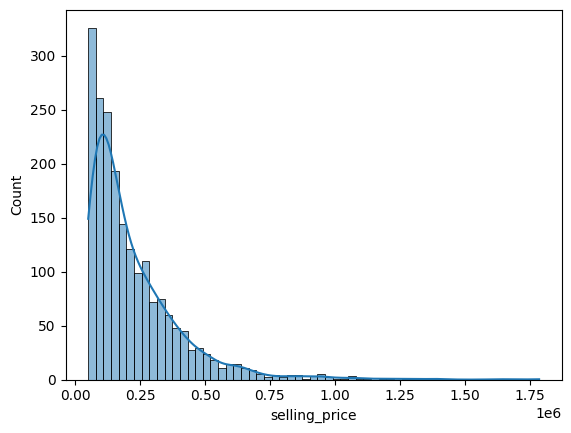

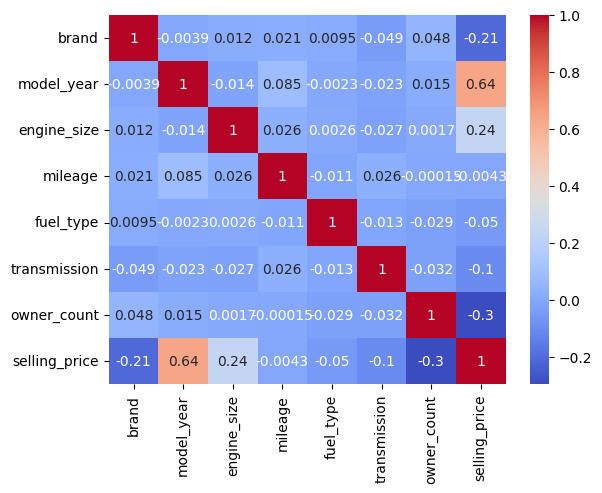

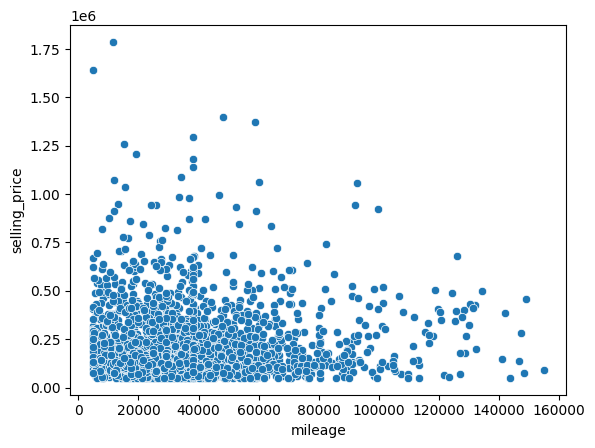

In [56]:
sns.histplot(dataset['selling_price'], kde=True)
plt.show()
sns.heatmap(dataset.corr(), annot=True, cmap="coolwarm")
plt.show()
sns.scatterplot(x=dataset["mileage"], y=dataset['selling_price'])
plt.show()


Lower Mileage demands Higher selling price. This trend is noticeable

Engine Size doesnt have a huge impact but does have some impact on selling price

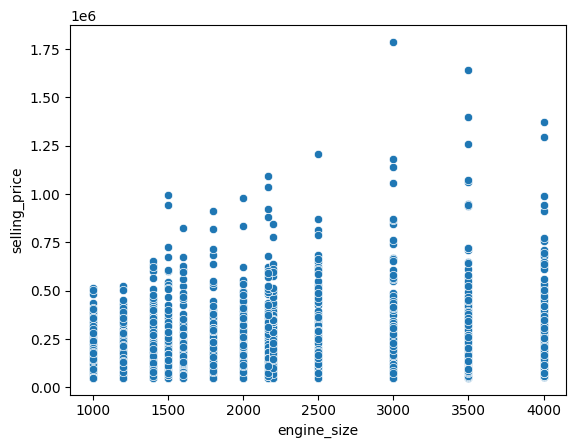

In [57]:
sns.scatterplot(x=dataset["engine_size"], y=dataset['selling_price'])
plt.show()

MOre recent Model years demand higher selling price on average

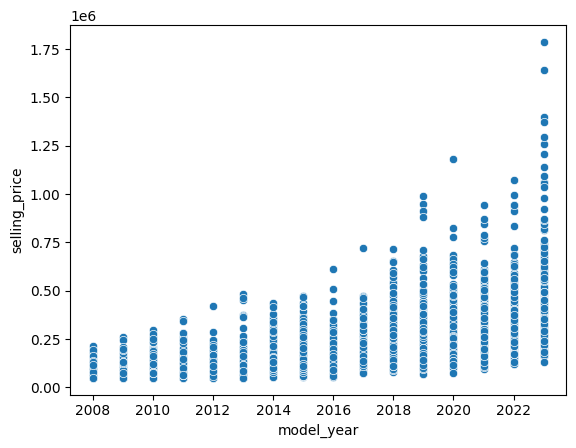

In [58]:
sns.scatterplot(x=dataset["model_year"], y=dataset['selling_price'])
plt.show()

Some brands determine a higher selling price on average than others as they are premium brands

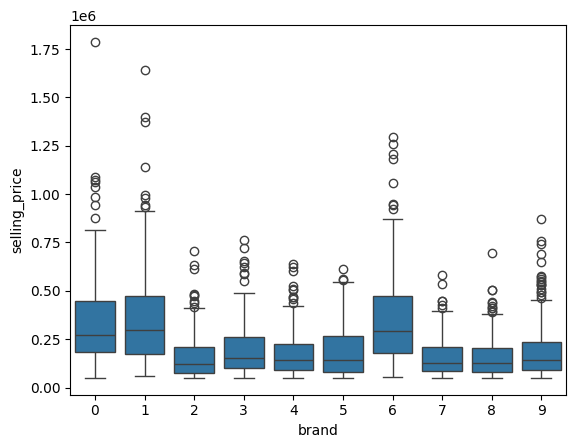

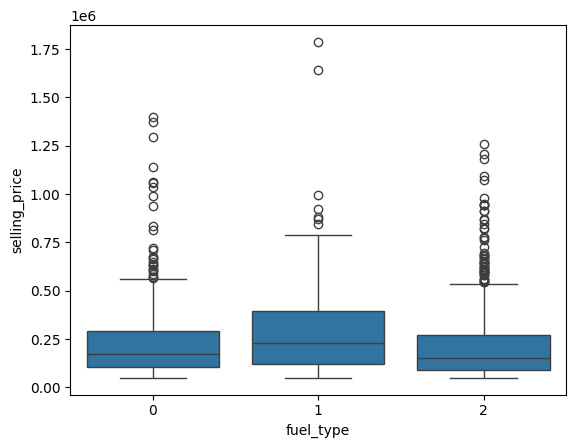

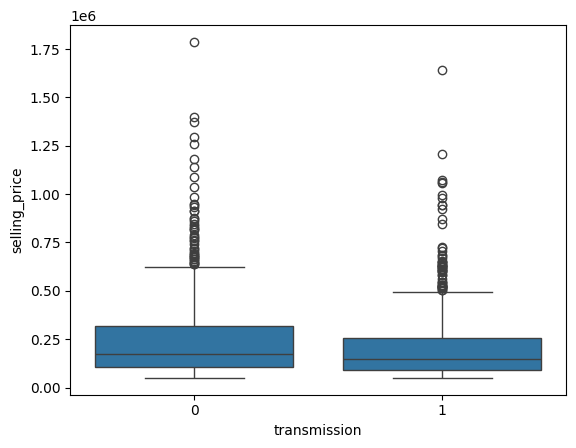

In [59]:
sns.boxplot(x=dataset["brand"], y=dataset['selling_price'])
plt.show()

sns.boxplot(x=dataset["fuel_type"], y=dataset['selling_price'])
plt.show()

sns.boxplot(x=dataset["transmission"], y=dataset['selling_price'])
plt.show()

In [60]:
scaler = StandardScaler()
dataset[["model_year", "engine_size", "mileage", "owner_count"]] = scaler.fit_transform(dataset[["model_year", "engine_size", "mileage", "owner_count"]])

In [61]:
y = dataset["selling_price"]
x = dataset.drop("selling_price", axis=1)

In [62]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [63]:
linear_regression = LinearRegression()
linear_model = linear_regression.fit(x_train, y_train)
linear_results = linear_model.predict(x_test)

In [64]:
random_forest = RandomForestRegressor(random_state=42)
rf_model = random_forest.fit(x_train, y_train)
rf_results = rf_model.predict(x_test)

In [65]:
mean_absolute_error(y_test, linear_results)

72461.78600902692

In [66]:
mean_squared_error(y_test, linear_results)

9453605394.399946

In [67]:
r2_score(y_test, linear_results)

0.6352798182421591

In [68]:
np.sqrt(mean_squared_error(y_test, linear_results))

np.float64(97229.65285549438)

In [69]:
mean_absolute_error(y_test, rf_results)

42920.76144278606

In [70]:
mean_squared_error(y_test, rf_results)

4960898556.262667

In [71]:
r2_score(y_test, rf_results)

0.8086084887577248

In [72]:
np.sqrt(mean_squared_error(y_test, rf_results))

np.float64(70433.64647853089)

r2 Score of Linear Regression is horrible so we will use Random Forest which has an r2 score of 0.80

In [73]:
print("Please enter the following car details to predict the price:")

user_input = {
    "brand": input("Brand: "),
    "model_year": int(input("Model Year: ")),
    "engine_size": float(input("Engine Size: ")),
    "mileage": float(input("Mileage: ")),
    "fuel_type": input("Fuel Type (Petrol/Diesel/Hybrid): "),
    "transmission": input("Transmission (Manual/Automatic): "),
    "owner_count": int(input("Owner Count: "))
}

data = pd.DataFrame([user_input])

Please enter the following car details to predict the price:
Brand: Suzuki
Model Year: 2015
Engine Size: 4
Mileage: 4
Fuel Type (Petrol/Diesel/Hybrid): Hybrid
Transmission (Manual/Automatic): Automatic
Owner Count: 1


In [74]:
label_encoder = joblib.load("brand_encoder.pkl")
data["brand"] = label_encoder.transform(data["brand"])
label_encoder = joblib.load("fuel_type_encoder.pkl")
data["fuel_type"] = label_encoder.transform(data["fuel_type"])
label_encoder = joblib.load("transmission_encoder.pkl")
data["transmission"] = label_encoder.transform(data["transmission"])
data[["model_year", "engine_size", "mileage", "owner_count"]] = scaler.transform(data[["model_year", "engine_size", "mileage", "owner_count"]])

In [75]:
print("Linear Regression Prediction:", (linear_model.predict(data))[0])
print("Random Forest Prediction:", (rf_model.predict(data))[0])

Linear Regression Prediction: 151791.64150209245
Random Forest Prediction: 158621.98


In [76]:
joblib.dump(linear_model, "car_price_linear_model.pkl")
joblib.dump(rf_model, "car_price_rf_model.pkl")
joblib.dump(scaler, "car_scaler.pkl")

['car_scaler.pkl']